# InsightReach — Integración API Yelp
## Notebook 2: Oferta real de restaurantes en Chicago

**Fuente:** Yelp Fusion API — Chicago  
**Autor:** Mauricio Melgarejo


## 1. Importación de librerías

In [35]:
import pandas as pd
import requests
import numpy as np
import openpyxl
import matplotlib.pyplot as plt
import seaborn as sns

In [36]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [37]:
COLOR_PRINCIPAL  = "#2D6A4F"
COLOR_SECUNDARIO = "#95D5B2"
COLOR_ACENTO     = "#B7B7B7"
COLOR_HIGHLIGHT  = "#1B4332"

## 2. Configuración de la API

In [38]:
#url de la API
api_url='https://api.yelp.com/v3/businesses/search'

#estos datos corresponden a una cuenta de usuario creada previamente
clientid='GWOCZh9-BmZxtdsAjr7Gug'
apikey='FHVvXoNmTXIl9DuxYis7AV5uLPujm9MLwrhgs5NgvCfaOxd3V6mxt6dQU8eEqYJiGxe816XATx7ufWjbMWqbV-2Uku1jxBJv8BGRC74NroLPl27PDQqs0tDixit-YHYx'
headers={'Authorization':'Bearer %s'%apikey}

## 3. Consulta inicial

In [39]:
ciudad = "Chicago" # Se puede elegir cualquier ciudad del dataset entregado

In [40]:
# De esta manera se consulta el API de Yelp para obtener información sobre restaurantes en la ciudad especificada
params={'term':'restaurants','location': ciudad,'limit':50}
response=requests.get(api_url,params=params,headers=headers)
data=response.json()
data

{'businesses': [{'id': 'qjnpkS8yZO8xcyEIy5OU9A',
   'alias': 'girl-and-the-goat-chicago',
   'name': 'Girl & The Goat',
   'image_url': 'https://s3-media0.fl.yelpcdn.com/bphoto/ya6gjD4BPlxe7AKMj_5WsA/o.jpg',
   'is_closed': False,
   'url': 'https://www.yelp.com/biz/girl-and-the-goat-chicago?adjust_creative=GWOCZh9-BmZxtdsAjr7Gug&utm_campaign=yelp_api_v3&utm_medium=api_v3_business_search&utm_source=GWOCZh9-BmZxtdsAjr7Gug',
   'review_count': 10667,
   'categories': [{'alias': 'newamerican', 'title': 'New American'},
    {'alias': 'bars', 'title': 'Bars'},
    {'alias': 'bakeries', 'title': 'Bakeries'}],
   'rating': 4.4,
   'coordinates': {'latitude': 41.88419277030351,
    'longitude': -87.64794613195826},
   'transactions': ['delivery'],
   'price': '$$$',
   'location': {'address1': '809 W Randolph',
    'address2': '',
    'address3': '',
    'city': 'Chicago',
    'zip_code': '60607',
    'country': 'US',
    'state': 'IL',
    'display_address': ['809 W Randolph', 'Chicago, IL 60

In [41]:
#Veamos los keys del diccionario recibido
data.keys()

dict_keys(['businesses', 'total', 'region'])

In [42]:
#El primer elemento del diccionario indica el total de restaurants existentes en la API
print('En total la base de datos registra %d restaurants'%data['total'])

En total la base de datos registra 7800 restaurants


In [43]:
data['businesses'] # Hasta acá se le entregaría a los estudiantes

[{'id': 'qjnpkS8yZO8xcyEIy5OU9A',
  'alias': 'girl-and-the-goat-chicago',
  'name': 'Girl & The Goat',
  'image_url': 'https://s3-media0.fl.yelpcdn.com/bphoto/ya6gjD4BPlxe7AKMj_5WsA/o.jpg',
  'is_closed': False,
  'url': 'https://www.yelp.com/biz/girl-and-the-goat-chicago?adjust_creative=GWOCZh9-BmZxtdsAjr7Gug&utm_campaign=yelp_api_v3&utm_medium=api_v3_business_search&utm_source=GWOCZh9-BmZxtdsAjr7Gug',
  'review_count': 10667,
  'categories': [{'alias': 'newamerican', 'title': 'New American'},
   {'alias': 'bars', 'title': 'Bars'},
   {'alias': 'bakeries', 'title': 'Bakeries'}],
  'rating': 4.4,
  'coordinates': {'latitude': 41.88419277030351,
   'longitude': -87.64794613195826},
  'transactions': ['delivery'],
  'price': '$$$',
  'location': {'address1': '809 W Randolph',
   'address2': '',
   'address3': '',
   'city': 'Chicago',
   'zip_code': '60607',
   'country': 'US',
   'state': 'IL',
   'display_address': ['809 W Randolph', 'Chicago, IL 60607']},
  'phone': '+13124926262',
  

## 4. Procesamiento de datos 

In [44]:
# Convertir a DataFrame
df_yelp = pd.DataFrame(data['businesses'])

print(f"Negocios obtenidos: {len(df_yelp)}")
print(f"Columnas: {df_yelp.columns.tolist()}")

Negocios obtenidos: 50
Columnas: ['id', 'alias', 'name', 'image_url', 'is_closed', 'url', 'review_count', 'categories', 'rating', 'coordinates', 'transactions', 'price', 'location', 'phone', 'display_phone', 'distance']


In [45]:
# Quedarse solo con las columnas útiles
columnas_utiles = ['name', 'alias', 'categories', 'rating', 
                   'review_count', 'price', 'location', 'distance']

df_yelp = df_yelp[columnas_utiles]
display(df_yelp.head())

,name,alias,categories,rating,review_count,price,location,distance
0,Girl & The Goat,girl-and-the-goat-chicago,"[{'alias': 'newamerican', 'title': 'New Americ...",4.4,10667,$$$,"{'address1': '809 W Randolph', 'address2': '',...",3401.238676
1,The Purple Pig,the-purple-pig-chicago,"[{'alias': 'tapasmallplates', 'title': 'Tapas/...",4.3,8983,$$$,"{'address1': '444 N Michigan Ave', 'address2':...",4672.658118
2,Cindy's Rooftop,cindys-rooftop-chicago,"[{'alias': 'newamerican', 'title': 'New Americ...",4.1,2812,$$$,"{'address1': '12 S Michigan Ave', 'address2': ...",5091.190048
3,The Dearborn,the-dearborn-chicago-2,"[{'alias': 'newamerican', 'title': 'New Americ...",4.4,2739,$$,"{'address1': '145 N Dearborn St', 'address2': ...",4637.043533
4,Ciccio Mio,ciccio-mio-chicago-2,"[{'alias': 'italian', 'title': 'Italian'}]",4.7,632,$$$,"{'address1': '226 W Kinzie', 'address2': '', '...",3943.404234


In [46]:
# Extraer el título de la primera categoría
df_yelp['categoria'] = df_yelp['categories'].apply(
    lambda x: x[0]['title'] if x else None
)

# Extraer la ciudad de location
df_yelp['ciudad'] = df_yelp['location'].apply(
    lambda x: x['city'] if x else None
)

# Sacar las columnas originales anidadas
df_yelp = df_yelp.drop(columns=['categories', 'location'])

display(df_yelp.head())

,name,alias,rating,review_count,price,distance,categoria,ciudad
0,Girl & The Goat,girl-and-the-goat-chicago,4.4,10667,$$$,3401.238676,New American,Chicago
1,The Purple Pig,the-purple-pig-chicago,4.3,8983,$$$,4672.658118,Tapas/Small Plates,Chicago
2,Cindy's Rooftop,cindys-rooftop-chicago,4.1,2812,$$$,5091.190048,New American,Chicago
3,The Dearborn,the-dearborn-chicago-2,4.4,2739,$$,4637.043533,New American,Chicago
4,Ciccio Mio,ciccio-mio-chicago-2,4.7,632,$$$,3943.404234,Italian,Chicago


In [47]:
# Estructura del dataset de Yelp
print(f"Restaurantes obtenidos: {len(df_yelp)}")
print(f"Columnas: {df_yelp.shape[1]}")

# Tipos de datos
print(df_yelp.dtypes)

# Nulos
display(pd.DataFrame({
    "Nulos": df_yelp.isnull().sum(),
    "Porcentaje (%)": (df_yelp.isnull().sum() / len(df_yelp) * 100).round(2)
}))

Restaurantes obtenidos: 50
Columnas: 8
name                str
alias               str
rating          float64
review_count      int64
price               str
distance        float64
categoria           str
ciudad              str
dtype: object


,Nulos,Porcentaje (%)
name,0,0.0
alias,0,0.0
rating,0,0.0
review_count,0,0.0
price,16,32.0
distance,0,0.0
categoria,0,0.0
ciudad,0,0.0


In [48]:
# Imputar nulos en price
df_yelp["price"] = df_yelp["price"].fillna("No disponible")

# Verificar
print(df_yelp["price"].isnull().sum())

0


## 5. Paginación — 200 restaurantes

In [49]:
# Traer hasta 200 restaurantes con paginación
todos_los_negocios = []

for offset in range(0, 200, 50):
    params = {
        'term': 'restaurants',
        'location': ciudad,
        'limit': 50,
        'offset': offset
    }
    response = requests.get(api_url, params=params, headers=headers)
    data = response.json()
    
    if 'businesses' in data:
        todos_los_negocios.extend(data['businesses'])
    else:
        break

print(f"Total restaurantes obtenidos: {len(todos_los_negocios)}")

Total restaurantes obtenidos: 200


In [50]:
# Convertir a DataFrame
df_yelp = pd.DataFrame(todos_los_negocios)

# Quedarse con columnas útiles
columnas_utiles = ['name', 'alias', 'categories', 'rating', 
                   'review_count', 'price', 'location', 'distance']
df_yelp = df_yelp[columnas_utiles]

# Extraer categoria y ciudad
df_yelp['categoria'] = df_yelp['categories'].apply(
    lambda x: x[0]['title'] if x else None
)
df_yelp['ciudad'] = df_yelp['location'].apply(
    lambda x: x['city'] if x else None
)

# Eliminar columnas anidadas
df_yelp = df_yelp.drop(columns=['categories', 'location'])

# Imputar nulos en price
df_yelp['price'] = df_yelp['price'].fillna('No disponible')

print(f"Restaurantes: {len(df_yelp)}")
print(f"Columnas: {df_yelp.columns.tolist()}")
display(df_yelp.head())

Restaurantes: 200
Columnas: ['name', 'alias', 'rating', 'review_count', 'price', 'distance', 'categoria', 'ciudad']


,name,alias,rating,review_count,price,distance,categoria,ciudad
0,Girl & The Goat,girl-and-the-goat-chicago,4.4,10667,$$$,3401.238676,New American,Chicago
1,The Purple Pig,the-purple-pig-chicago,4.3,8983,$$$,4672.658118,Tapas/Small Plates,Chicago
2,Cindy's Rooftop,cindys-rooftop-chicago,4.1,2812,$$$,5091.190048,New American,Chicago
3,The Dearborn,the-dearborn-chicago-2,4.4,2739,$$,4637.043533,New American,Chicago
4,Ciccio Mio,ciccio-mio-chicago-2,4.7,632,$$$,3943.404234,Italian,Chicago


## 6. Análisis exploratorio

In [51]:
# Distribución por categoria
display(df_yelp["categoria"].value_counts().head(10))

categoria
New American      19
Italian           17
Mediterranean     10
Thai               9
American           9
Mexican            9
Steakhouses        8
Cocktail Bars      7
Bars               6
Latin American     6
Name: count, dtype: int64

In [52]:
# Distribución por precio
display(df_yelp["price"].value_counts())

price
$$               74
No disponible    73
$$$              41
$$$$             11
$                 1
Name: count, dtype: int64

In [53]:
# Estadísticas de rating y review_count
display(df_yelp[["rating", "review_count", "distance"]].describe().round(2))

,rating,review_count,distance
count,200.00,200.00,200.00
mean,4.38,740.66,3276.50
std,0.26,1480.46,1944.94
min,3.60,4.00,196.31
25%,4.20,105.75,1473.04
50%,4.40,272.50,3389.22
75%,4.50,648.50,4249.90
max,5.00,10667.00,10889.88


### Confiabilidad de los ratings

In [54]:
# Distribucion de reseñas
print("Estadisticas de review_count:")
display(df_yelp["review_count"].describe().round(0))

# Ver cuantos restaurantes hay por rango de reseñas
rangos = [0, 10, 50, 100, 500, 1000, df_yelp["review_count"].max()]
etiquetas = ["1-10", "11-50", "51-100", "101-500", "501-1000", "1000+"]
df_yelp["rango_reseñas"] = pd.cut(df_yelp["review_count"], bins=rangos, labels=etiquetas)
display(df_yelp["rango_reseñas"].value_counts().sort_index())

Estadisticas de review_count:


count      200.0
mean       741.0
std       1480.0
min          4.0
25%        106.0
50%        272.0
75%        648.0
max      10667.0
Name: review_count, dtype: float64

rango_reseñas
1-10         5
11-50       24
51-100      20
101-500     82
501-1000    34
1000+       35
Name: count, dtype: int64

In [55]:
# Definir umbral de confiabilidad
UMBRAL_RESEÑAS = 50

# Separar confiables de no confiables
df_yelp_confiable = df_yelp[df_yelp["review_count"] >= UMBRAL_RESEÑAS].copy()
df_yelp_no_confiable = df_yelp[df_yelp["review_count"] < UMBRAL_RESEÑAS].copy()

print(f"Umbral definido: {UMBRAL_RESEÑAS} reseñas minimas")
print(f"Restaurantes confiables: {len(df_yelp_confiable)} ({len(df_yelp_confiable)/len(df_yelp)*100:.1f}%)")
print(f"Restaurantes descartados: {len(df_yelp_no_confiable)} ({len(df_yelp_no_confiable)/len(df_yelp)*100:.1f}%)")

Umbral definido: 50 reseñas minimas
Restaurantes confiables: 172 (86.0%)
Restaurantes descartados: 28 (14.0%)


Se analiza la distribución de reseñas para definir el umbral de confianza del rating ponderado.
Con m=50 los restaurantes con pocas reseñas ven su rating ajustado hacia el promedio global.

### Rating ponderado Bayesiano

In [56]:
# Rating ponderado Bayesiano
C = df_yelp["rating"].mean()  # promedio global de todos los restaurantes
m = 50                         # umbral de confianza — mismo valor que usamos antes

df_yelp["rating_ponderado"] = (
    (df_yelp["review_count"] * df_yelp["rating"] + m * C) /
    (df_yelp["review_count"] + m)
).round(2)

print(f"Promedio global C: {C:.2f}")
print(f"Umbral de confianza m: {m}")
print()
print("Comparacion rating original vs ponderado:")
display(df_yelp[["name", "rating", "review_count", "rating_ponderado"]].sort_values("review_count").head(10))

Promedio global C: 4.38
Umbral de confianza m: 50

Comparacion rating original vs ponderado:


,name,rating,review_count,rating_ponderado
145,Susu,4.3,4,4.38
13,Qing Xiang Yuan Dumplings,4.3,6,4.37
109,This Little Goat,4.0,6,4.34
70,Ardor by Chance,4.8,9,4.45
58,Sho,4.9,10,4.47
24,Libertad,4.5,12,4.41
87,La Bodega,5.0,15,4.53
126,Hattie B's Hot Chicken,4.5,16,4.41
193,Galata Mediterranean Grill,5.0,18,4.55
57,La Mom Kitchen,4.9,23,4.55


In [57]:
# Ver el efecto en los restaurantes con muchas resenas
print("Restaurantes con mas resenas — casi no cambian:")
display(df_yelp[["name", "rating", "review_count", "rating_ponderado"]].sort_values("review_count", ascending=False).head(10))

# Diferencia promedio
diferencia = (df_yelp["rating_ponderado"] - df_yelp["rating"]).abs().mean()
print(f"\nDiferencia promedio entre rating original y ponderado: {diferencia:.3f}")

Restaurantes con mas resenas — casi no cambian:


,name,rating,review_count,rating_ponderado
0,Girl & The Goat,4.4,10667,4.4
15,Au Cheval,4.4,9492,4.4
1,The Purple Pig,4.3,8983,4.3
79,Pequod's Pizza,3.9,8886,3.9
131,Cafe Ba-Ba-Reeba!,4.3,5149,4.3
55,The Gage,4.2,3693,4.2
14,Bavette's Bar & Boeuf,4.5,3501,4.5
2,Cindy's Rooftop,4.1,2812,4.1
28,Alinea,4.4,2759,4.4
3,The Dearborn,4.4,2739,4.4



Diferencia promedio entre rating original y ponderado: 0.052


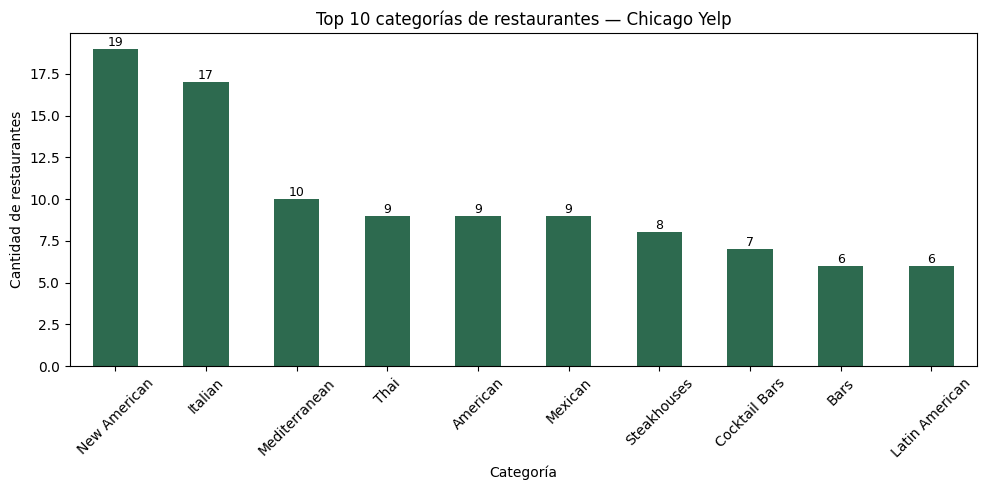

In [58]:
ax = df_yelp["categoria"].value_counts().head(10).plot(
    kind="bar",
    figsize=(10, 5),
    color=COLOR_PRINCIPAL
)
# Valores encima de las barras
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
               (p.get_x() + p.get_width()/2, p.get_height()),
               ha='center', va='bottom', fontsize=9)

plt.title("Top 10 categorías de restaurantes — Chicago Yelp")
plt.xlabel("Categoría")
plt.ylabel("Cantidad de restaurantes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

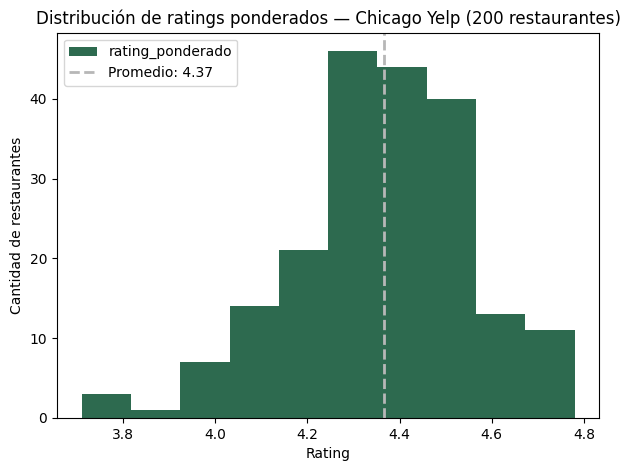

In [59]:
# Distribución de ratings — solo restaurantes confiables (50+ reseñas)
ax = df_yelp["rating_ponderado"].plot(
    kind="hist",
    bins=10,
    figsize=(7, 5),
    color=COLOR_PRINCIPAL
)
promedio_rating = df_yelp["rating_ponderado"].mean()
ax.axvline(promedio_rating, color=COLOR_ACENTO,
          linestyle="--", linewidth=2,
          label=f'Promedio: {promedio_rating:.2f}')
ax.legend()
plt.title("Distribución de ratings ponderados — Chicago Yelp (200 restaurantes)")
plt.xlabel("Rating")
plt.ylabel("Cantidad de restaurantes")
plt.show()

Rating ponderado Bayesiano aplicado sobre los 200 restaurantes.
Los ratings se concentran entre 4.2 y 4.6 — distribución más confiable que el rating original.

In [60]:
# Ver todas las categorías únicas
print(df_yelp["categoria"].value_counts())

categoria
New American          19
Italian               17
Mediterranean         10
Thai                   9
American               9
Mexican                9
Steakhouses            8
Cocktail Bars          7
Bars                   6
Latin American         6
Asian Fusion           5
Japanese               5
Korean                 5
Indian                 4
Chinese                4
Greek                  4
Seafood                3
Tacos                  3
Ramen                  3
French                 3
Modern European        3
Tapas/Small Plates     2
Dim Sum                2
Pasta Shops            2
Peruvian               2
British                2
Filipino               2
Pizza                  2
Food Court             2
Turkish                2
Sushi Bars             2
Brasseries             2
Southern               2
Spanish                2
Cuban                  2
Burgers                2
Breweries              1
Wine Bars              1
Barbeque               1
Specialty Food 

## 7. Integración con el Notebook 1


In [61]:
# Diccionario que relaciona categorias Yelp con preferencias del Avance 1
mapeo = {
    # Carnes
    "New American": "Carnes",
    "Italian": "Carnes",
    "Mexican": "Carnes",
    "American": "Carnes",
    "Steakhouses": "Carnes",
    "Latin American": "Carnes",
    "Korean": "Carnes",
    "French": "Carnes",
    "Southern": "Carnes",
    "Barbeque": "Carnes",
    "Argentine": "Carnes",
    "Soul Food": "Carnes",
    "Cajun/Creole": "Carnes",
    "Chicken Wings": "Carnes",
    "Burgers": "Carnes",
    "Cuban": "Carnes",
    "Filipino": "Carnes",
    "Turkish": "Carnes",
    "Ukrainian": "Carnes",
    "Polish": "Carnes",
    "British": "Carnes",
    "Comfort Food": "Carnes",
    "Supper Clubs": "Carnes",
    # Pescado / Mariscos
    "Mediterranean": "Pescado",
    "Seafood": "Mariscos",
    "Sushi Bars": "Mariscos",
    "Japanese": "Mariscos",
    "Shanghainese": "Mariscos",
    "Vietnamese": "Mariscos",
    "Cambodian": "Mariscos",
    "Laotian": "Mariscos",
    "Indonesian": "Mariscos",
    # Vegetariano / Vegano
    "Thai": "Vegetariano",
    "Asian Fusion": "Vegetariano",
    "Indian": "Vegetariano",
    "Chinese": "Vegetariano",
    "Vegetarian": "Vegano",
    "Salad": "Vegano",
    # Otro
    "Cocktail Bars": "Otro",
    "Bars": "Otro",
    "Wine Bars": "Otro",
    "Breweries": "Otro",
    "Brewpubs": "Otro",
    "Pubs": "Otro",
    "Tapas/Small Plates": "Otro",
    "Dim Sum": "Otro",
    "Ramen": "Otro",
    "Pizza": "Otro",
    "Pasta Shops": "Otro",
    "Szechuan": "Otro",
    "Peruvian": "Otro",
    "Tacos": "Otro",
    "Spanish": "Otro",
    "Greek": "Otro",
    "Modern European": "Otro",
    "Food Court": "Otro",
    "Cafes": "Otro",
    "Specialty Food": "Otro",
    "Brasseries": "Otro",
    "Lebanese": "Otro",
    "African": "Otro",
    "Restaurants": "Otro",
    "Caterers": "Otro",
    "Desserts": "Otro",
    "Sandwiches": "Otro",
}

# Aplicar mapeo
df_yelp["preferencia"] = df_yelp["categoria"].map(mapeo).fillna("Otro")

# Verificar resultado
display(df_yelp["preferencia"].value_counts())

preferencia
Carnes         96
Otro           57
Vegetariano    22
Mariscos       13
Pescado        10
Vegano          2
Name: count, dtype: int64

In [62]:
# Guardar CSV con rating ponderado incluido
df_yelp.to_csv("yelp_chicago.csv", index=False)
print("Guardado correctamente con rating ponderado.")
print(f"Columnas: {df_yelp.columns.tolist()}")

Guardado correctamente con rating ponderado.
Columnas: ['name', 'alias', 'rating', 'review_count', 'price', 'distance', 'categoria', 'ciudad', 'rango_reseñas', 'rating_ponderado', 'preferencia']


## Conclusiones

200 restaurantes obtenidos de Chicago — New American domina.
Rating ponderado Bayesiano aplicado — ajusta ratings con pocas reseñas hacia el promedio global.
Categorías mapeadas con preferencias del Notebook 1 — dataset listo para integración.
